In [1]:
import matplotlib.pyplot as plt


In [2]:
import pandas as pd
import io
from google.colab import files

uploaded = files.upload()
df = pd.read_csv(io.StringIO(uploaded['cleaned_data.csv'].decode('utf-8')))


Saving cleaned_data.csv to cleaned_data.csv


In [3]:
plot_data = df.dropna(subset=["Location", "Focus_Rating"]).copy()

In [4]:
locations = sorted(plot_data["Location"].unique())

/tmp/ipykernel_3191/1447965197.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


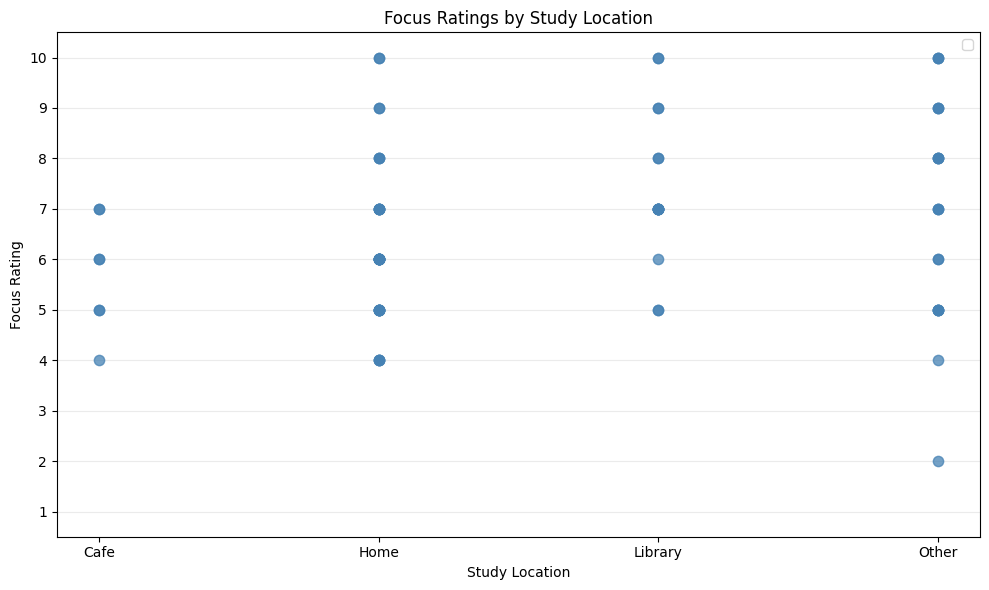

In [6]:
location_positions ={location: i for i, location in enumerate(locations)}
x = plot_data["Location"].map(location_positions)
fig,ax = plt.subplots(figsize=(10,6))
ax.scatter(x,plot_data["Focus_Rating"],color="steelblue", s=55, alpha=0.75)

ax.set_xticks(range(len(locations)))
ax.set_xticklabels(locations)
ax.set_xlabel("Study Location")
ax.set_ylabel("Focus Rating")
ax.set_title("Focus Ratings by Study Location")

ax.set_ylim(0.5,10.5)
ax.set_yticks(range(1,11))
ax.grid(axis="y", alpha = 0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.legend(loc='upper right')
plt.show()

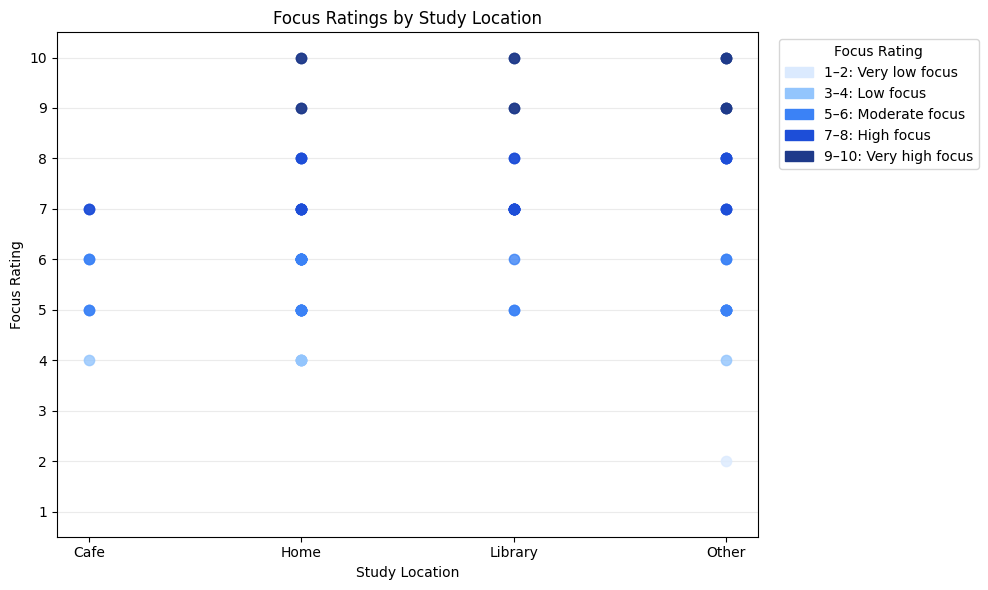

In [8]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Keep rows with valid location and focus rating
plot_data1 = df.dropna(subset=["Location", "Focus_Rating"]).copy()

locations1 = sorted(plot_data["Location"].unique())

location_positions1 = {
    location: i for i, location in enumerate(locations1)
}

x = plot_data1["Location"].map(location_positions1)

# Group focus ratings into categories
def rating_group(rating):
    if rating <= 2:
        return "1–2: Very low focus"
    elif rating <= 4:
        return "3–4: Low focus"
    elif rating <= 6:
        return "5–6: Moderate focus"
    elif rating <= 8:
        return "7–8: High focus"
    else:
        return "9–10: Very high focus"

plot_data1["Rating_Group"] = plot_data1["Focus_Rating"].apply(rating_group)

# Assign a color to each rating group
colors = {
    "1–2: Very low focus": "#dbeafe",
    "3–4: Low focus": "#93c5fd",
    "5–6: Moderate focus": "#3b82f6",
    "7–8: High focus": "#1d4ed8",
    "9–10: Very high focus": "#1e3a8a"
}

fig, ax = plt.subplots(figsize=(10, 6))

# Plot each rating group separately
for group, color in colors.items():
    subset = plot_data1[plot_data1["Rating_Group"] == group]

    ax.scatter(
        subset["Location"].map(location_positions1),
        subset["Focus_Rating"],
        color=color,
        s=55,
        alpha=0.8
    )

# Add a legend
legend_handles = [
    mpatches.Patch(color=color, label=group)
    for group, color in colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Focus Rating",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.set_xticks(range(len(locations1)))
ax.set_xticklabels(locations1)
ax.set_xlabel("Study Location")
ax.set_ylabel("Focus Rating")
ax.set_title("Focus Ratings by Study Location")

ax.set_ylim(0.5, 10.5)
ax.set_yticks(range(1, 11))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


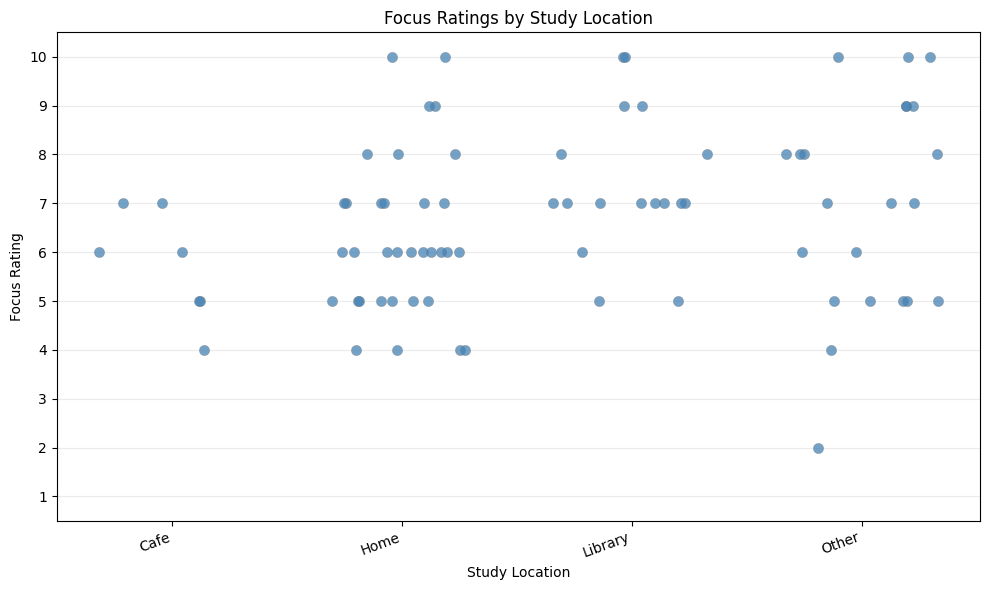

In [13]:

import matplotlib.pyplot as plt
import numpy as np

# Keep sessions with valid location and focus rating
plot_data = df.dropna(
    subset=["Location", "Focus_Rating"]
).copy()

locations = sorted(plot_data["Location"].unique())

location_positions = {
    location: i for i, location in enumerate(locations)
}

# Jitter points horizontally to reduce overlap
rng = np.random.default_rng(42)

x = (
    plot_data["Location"].map(location_positions).to_numpy()
    + rng.uniform(-0.35, 0.35, size=len(plot_data))
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x,
    plot_data["Focus_Rating"],
    color="steelblue",
    s=55,
    alpha=0.75,
    edgecolors="gray",
    linewidths=0.3
)

ax.set_xticks(range(len(locations)))
ax.set_xticklabels(locations, rotation=20, ha="right")
ax.set_xlabel("Study Location")
ax.set_ylabel("Focus Rating")
ax.set_title("Focus Ratings by Study Location")

ax.set_ylim(0.5, 10.5)
ax.set_yticks(range(1, 11))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


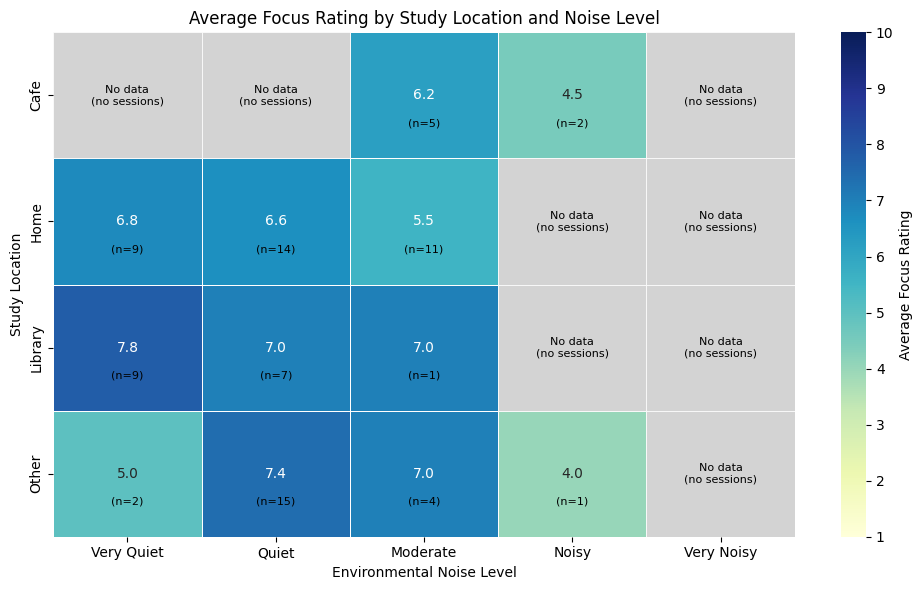

In [18]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Keep sessions with valid values for all three variables
heatmap_data = df.dropna(
    subset=["Location", "Noise_Level", "Focus_Rating"]
).copy()

# Calculate average focus rating for each combination
avg_focus = heatmap_data.pivot_table(
    index="Location",
    columns="Noise_Level",
    values="Focus_Rating",
    aggfunc="mean"
)

# Count the number of sessions in each combination
session_counts = heatmap_data.pivot_table(
    index="Location",
    columns="Noise_Level",
    values="Focus_Rating",
    aggfunc="count",
    fill_value=0
)

# Keep the same ordering of categories in both tables
noise_order = [
    "Very Quiet",
    "Quiet",
    "Moderate",
    "Noisy",
    "Very Noisy"
]

location_order = sorted(heatmap_data["Location"].unique())

avg_focus = avg_focus.reindex(
    index=location_order,
    columns=noise_order
)

session_counts = session_counts.reindex(
    index=location_order,
    columns=noise_order,
    fill_value=0
)

# Annotate each cell with average focus and session count
annotations = avg_focus.copy().astype(object)

for location in avg_focus.index:
    for noise in avg_focus.columns:
        average = avg_focus.loc[location, noise]
        count = session_counts.loc[location, noise]

        if pd.isna(average) or count == 0:
            annotations.loc[location, noise] = "No data"
        else:
            annotations.loc[location, noise] = (
                f"{average:.1f}\n(n={count})"
            )


fig, ax = plt.subplots(figsize=(10, 6))

# Draw the heatmap, masking cells with no sessions
sns.heatmap(
    avg_focus,
    annot=avg_focus.where(avg_focus.notna()),
    fmt=".1f",
    mask=avg_focus.isna(),
    cmap="YlGnBu",
    vmin=1,
    vmax=10,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Average Focus Rating"},
    ax=ax
)

# Add labels and session counts to cells with data
for i, location in enumerate(avg_focus.index):
    for j, noise in enumerate(avg_focus.columns):
        average = avg_focus.loc[location, noise]
        count = session_counts.loc[location, noise]

        if pd.isna(average) or count == 0:
            # Draw a light-gray background for missing cells
            ax.add_patch(
                plt.Rectangle(
                    (j, i), 1, 1,
                    facecolor="lightgray",
                    edgecolor="white",
                    linewidth=0.5
                )
            )

            # Add the missing-data label
            ax.text(
                j + 0.5, i + 0.5,
                "No data\n(no sessions)",
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )
        else:
            # Add session count beneath the average
            ax.text(
                j + 0.5, i + 0.72,
                f"(n={count})",
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

ax.set_title("Average Focus Rating by Study Location and Noise Level")
ax.set_xlabel("Environmental Noise Level")
ax.set_ylabel("Study Location")

plt.tight_layout()
plt.show()


In [14]:
import pandas as pd

# Keep rows with valid location and noise categories
check_data = df.dropna(subset=["Location", "Noise_Level"]).copy()

# Count sessions for each location-noise combination
session_counts = pd.crosstab(
    check_data["Location"],
    check_data["Noise_Level"]
)

# Include all expected noise categories
noise_order = [
    "Very Quiet", "Quiet", "Moderate", "Noisy", "Very Noisy"
]

session_counts = session_counts.reindex(
    columns=noise_order,
    fill_value=0
)

print("Session counts for each combination:")
display(session_counts)

print("\nCombinations with zero sessions:")
display(session_counts[session_counts == 0].stack().rename("Session_Count").reset_index())

Session counts for each combination:


Noise_Level,Very Quiet,Quiet,Moderate,Noisy,Very Noisy
Location,,,,,
Cafe,0,0,5,2,0
Home,9,14,11,0,0
Library,9,7,1,0,0
Other,2,15,4,1,0



Combinations with zero sessions:


,Location,Noise_Level,Session_Count
0,Cafe,Very Quiet,0.0
1,Cafe,Quiet,0.0
2,Cafe,Very Noisy,0.0
3,Home,Noisy,0.0
4,Home,Very Noisy,0.0
5,Library,Noisy,0.0
6,Library,Very Noisy,0.0
7,Other,Very Noisy,0.0


In [15]:
focus_check = df.groupby(
    ["Location", "Noise_Level"],
    dropna=False
).agg(
    Total_Sessions=("Focus_Rating", "size"),
    Available_Focus_Ratings=("Focus_Rating", "count")
).reset_index()

focus_check["Missing_Focus_Ratings"] = (
    focus_check["Total_Sessions"]
    - focus_check["Available_Focus_Ratings"]
)

display(focus_check)

,Location,Noise_Level,Total_Sessions,Available_Focus_Ratings,Missing_Focus_Ratings
0,Cafe,Moderate,5,5,0
1,Cafe,Noisy,2,2,0
2,Home,Moderate,11,11,0
3,Home,Quiet,14,14,0
4,Home,Very Quiet,9,9,0
5,Library,Moderate,1,1,0
6,Library,Quiet,7,7,0
7,Library,Very Quiet,9,9,0
8,Other,Moderate,4,4,0
9,Other,Noisy,1,1,0


In [16]:
print("Location categories:")
print(df["Location"].value_counts(dropna=False).to_string())

print("\nNoise level categories:")
print(df["Noise_Level"].value_counts(dropna=False).to_string())

# Check for leading or trailing spaces
for column in ["Location", "Noise_Level"]:
    print(f"\nExtra spaces in {column}:")
    print(
        df.loc[
            df[column].notna()
            & (df[column] != df[column].str.strip()),
            column
        ].unique()
    )

Location categories:
Location
Home       34
Other      22
Library    17
Cafe        7

Noise level categories:
Noise_Level
Quiet         36
Moderate      21
Very Quiet    20
Noisy          3

Extra spaces in Location:
[]

Extra spaces in Noise_Level:
[]


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output

# ==========================================
# 1. SETUP MOCK DATA (Matching your plots)
# ==========================================
locations = ['Cafe', 'Home', 'Library', 'Other']
noise_levels = ['Very Quiet', 'Quiet', 'Moderate', 'Noisy', 'Very Noisy']

# Aggregated Heatmap Matrix (Averages)
heatmap_matrix = np.array([
    [np.nan, np.nan, 6.2, 4.5, np.nan],  # Cafe
    [6.8, 6.6, 5.5, np.nan, np.nan],     # Home
    [7.8, 7.0, 7.0, np.nan, np.nan],     # Library
    [5.0, 7.4, 7.0, 4.0, np.nan]          # Other
])

# Sample sizes mapping for text labels
sample_counts = {
    ('Cafe', 'Moderate'): 5, ('Cafe', 'Noisy'): 2,
    ('Home', 'Very Quiet'): 9, ('Home', 'Quiet'): 14, ('Home', 'Moderate'): 11,
    ('Library', 'Very Quiet'): 9, ('Library', 'Quiet'): 7, ('Library', 'Moderate'): 1,
    ('Other', 'Very Quiet'): 2, ('Other', 'Quiet'): 15, ('Other', 'Moderate'): 4, ('Other', 'Noisy'): 1
}

# Generate raw session data for the Jitter plot
np.random.seed(42)
sessions = []
for loc in locations:
    for noise in noise_levels:
        count = sample_counts.get((loc, noise), 0)
        mean_score = heatmap_matrix[locations.index(loc), noise_levels.index(noise)]

        if count > 0:
            for _ in range(count):
                score = np.clip(np.round(np.random.normal(mean_score, 1.0)), 1, 10)
                sessions.append({'Location': loc, 'Noise': noise, 'Score': score})

# ==========================================
# 2. PLOTTING FUNCTION WITH ENHANCED DOT VISIBILITY
# ==========================================
out = widgets.Output()

def update_dashboard(selected_location='All'):
    with out:
        clear_output(wait=True)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
        fig.suptitle(f"FocusTrace Dashboard — Filter: {selected_location}", fontsize=14, fontweight='bold', y=1.02)

        # --- PLOT 1: JITTER DOT PLOT (MICRO-VIEW - HIGH VISIBILITY) ---
        if selected_location == 'All':
            filtered_data = sessions
            title_suffix = "(All Locations)"
        else:
            filtered_data = [s for s in sessions if s['Location'] == selected_location]
            title_suffix = f"({selected_location} Only)"

        x_indices = [locations.index(s['Location']) for s in filtered_data]
        y_scores = [s['Score'] for s in filtered_data]

        # INCREASED JITTER: Changed from 0.15 to 0.25 to fan the dots out horizontally
        jitter = np.random.uniform(-0.25, 0.25, size=len(x_indices))
        x_jittered = np.array(x_indices) + jitter

        # VISIBILITY UPGRADES: Increased size (s=90), made opacity crisper (alpha=0.8), and gave bold borders
        ax1.scatter(x_jittered, y_scores, alpha=0.8, color='#1f5080', edgecolors='black', linewidths=0.8, s=90)

        ax1.set_xticks(range(len(locations)))
        ax1.set_xticklabels(locations, rotation=15, fontsize=10)
        ax1.set_ylabel('Focus Rating (1-10)', fontweight='bold', fontsize=11)
        ax1.set_xlabel('Study Location', fontweight='bold', fontsize=11)
        ax1.set_ylim(0.5, 10.5)
        ax1.set_yticks(range(1, 11)) # Crisp integer y-ticks to match focus ratings
        ax1.set_title(f'1. Jittered Session Spread {title_suffix}', fontsize=12, pad=10, fontweight='bold')
        ax1.grid(axis='both', linestyle='--', alpha=0.4) # Added faint vertical grid lines for easier alignment

        # --- PLOT 2: LOCATION-BY-NOISE HEATMAP WITH "NO DATA" CELLS ---
        annot_labels = np.empty(heatmap_matrix.shape, dtype=object)
        display_matrix = heatmap_matrix.copy()

        for r, loc in enumerate(locations):
            for c, noise in enumerate(noise_levels):
                val = heatmap_matrix[r, c]
                if np.isnan(val):
                    annot_labels[r, c] = "No Data\n(n=0)"
                    display_matrix[r, c] = -1.5
                else:
                    n = sample_counts.get((loc, noise), 0)
                    annot_labels[r, c] = f"{val:.1f}\n(n={n})"

        base_cmap = plt.cm.GnBu
        custom_colors = base_cmap(np.linspace(0, 1, 256))
        gray_under = np.array([234/255, 234/255, 234/255, 1.0])

        from matplotlib.colors import ListedColormap
        combined_colors = np.vstack([gray_under, custom_colors])
        cmap_with_gray = ListedColormap(combined_colors)

        sns.heatmap(display_matrix, annot=annot_labels, fmt="", cmap=cmap_with_gray,
                    xticklabels=noise_levels, yticklabels=locations, ax=ax2,
                    annot_kws={'weight': 'bold', 'size': 9}, vmin=0, vmax=10,
                    cbar_kws={'label': 'Average Focus Rating', 'ticks': list(range(0, 11))})

        ax2.set_xticklabels(noise_levels, rotation=20, ha='right', fontsize=10)
        ax2.set_yticklabels(locations, fontsize=10)
        ax2.set_xlabel('Environmental Noise Level', fontweight='bold', fontsize=11)
        ax2.set_ylabel('Study Location', fontweight='bold', fontsize=11)
        ax2.set_title('2. Aggregated Trends & Sample Sizes', fontsize=12, pad=10, fontweight='bold')

        # Highlight selection focus area
        if selected_location != 'All':
            row_idx = locations.index(selected_location)
            ax2.axhline(row_idx, color='red', linewidth=3.0)
            ax2.axhline(row_idx + 1, color='red', linewidth=3.0)

        plt.tight_layout()
        plt.show()

# ==========================================
# 3. INTERACTIVE CONTROLS CONTAINER
# ==========================================
dropdown = widgets.Dropdown(
    options=['All'] + locations,
    value='All',
    description='Filter Location:',
    disabled=False,
)

def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        update_dashboard(change['new'])

dropdown.observe(on_change)

display(dropdown, out)
update_dashboard('All')


Dropdown(description='Filter Location:', options=('All', 'Cafe', 'Home', 'Library', 'Other'), value='All')

Output()